In [1]:
# imports to enable the notebook to access the src folder
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))

# import the necessary packages
from src.molecules import StructuralValidator
from src.pure import PropertyCalculator
from src.pure import AntoineCalculator
from src.data import load_unifac_data
from src.mixture.unifac.pyomo_vle import pyo_vle
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# step1: define the compounds
mixture = {'ethanol': {'CH3':1, 'CH2':1, 'OH':1},
           'water': {'H2O':1}}
# validate the structures
validator = StructuralValidator()
validator.validate(mixture)

{'ethanol': True, 'water': True}

In [10]:
# step2: calculate the required properties
prop_list = ['tc', 'pc', 'tb', 'ac', 'hv']
pure_calc = PropertyCalculator()
pure_props = pure_calc.calculate(mixture, prop_list)

# fix the properties of ethanol
#pure_props['ethanol'] = {}  # make it a dict -------- WE ADDED IT!!!!!
pure_props['ethanol']['tc'] = 514.0
pure_props['ethanol']['pc'] = 61.4
pure_props['ethanol']['tb'] = 351.5
pure_props

{'ethanol': {'tc': 514.0,
  'pc': 61.4,
  'tb': 351.5,
  'ac': 0.5267339665342352,
  'hv': 40.124},
 'water': {'tc': 646.9999999999999,
  'pc': 220.6400000000002,
  'tb': 373.1499999999999,
  'ac': 0.3448609999999985,
  'hv': 43.9883}}

In [11]:
# step3: calculate the Antoine coefficients
#critical_properties = 
antoine_params = {}
antoine_calc = AntoineCalculator()
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, props, method='enthalpy_vap')  #we changed the syntax
    if results is None:   #we added this section
        print(f"Antoine calculation failed for {compound}")
        continue
    print('optimization results was', results['termination_condition'] )
    
    antoine_params[compound] = {}
    antoine_params[compound]['A'] = results['A']
    antoine_params[compound]['B'] = results['B']
    antoine_params[compound]['C'] = results['C']
antoine_params

Characteristic points (T [K], P [bar]): (298.15, 0.08685692745170667), (351.5, 1.01325), (514.0, 61.4)
optimization results was optimal
Characteristic points (T [K], P [bar]): (298.15, 0.028628051297286683), (373.1499999999999, 1.01325), (646.9999999999999, 220.6400000000002)
optimization results was optimal


{'ethanol': {'A': 5.249574125111119,
  'B': 1654.775088733013,
  'C': -35.93553534279516},
 'water': {'A': 5.082781262396579,
  'B': 1628.8997558336976,
  'C': -52.31505537521556}}

In [12]:
# step4: perform the vle
# define number of data points
n_data = 100
# set composition
x1 = np.linspace(0, 1, n_data)  # Component 1: 0 to 1
x2 = 1 - x1                     # Component 2: 1 to 0 (complement)
x = np.column_stack([x1, x2])  # Combine into 2D array
# provide nitial guess for temperature
# Extract boiling points
boiling_points = [props['tb'] for props in pure_props.values()]
T_min = min(boiling_points) 
T_max = max(boiling_points)  
T0 = np.linspace(T_min, T_max, n_data)
# Load all UNIFAC parameters
rk_data, qk_data, interaction_data = load_unifac_data()
# perform the VLE calculation
results, model = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=False)

gamma_pyo = np.empty_like(x)
T_pyo = np.empty_like(T0)
y_pyo = np.empty_like(x)
psat_pyo = np.empty_like(x)


for i in model.gamma.keys():
    gamma_pyo[i] = model.gamma[i].value

for i in model.T.keys():
    T_pyo[i] = model.T[i].value

for i in model.y.keys():
    y_pyo[i] = model.y[i].value

for i in model.psat.keys():
    psat_pyo[i] = model.psat[i].value

In [13]:
# step 5: find the azeotrope
T0_az = T_min#np.array((T_min+T_max)/2)
x0_az = np.array([[0.1, 0.9]])

In [18]:
from src.mixture.unifac.pyomo_azeo import pyo_azeo
T0_az = np.array((T_min+T_max)/2)
x0_az = np.array([[0.5, 0.5]])
results_az, model_az = pyo_azeo(x0_az, T0_az, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=False)

In [19]:
# retrieving the solutions
gamma_az = np.empty_like(x0_az)
T_az = np.empty_like(T0_az)
y_az = np.empty_like(x0_az)
x_az = np.empty_like(x0_az)
psat_az = np.empty_like(x0_az)


for i in model_az.gamma.keys():
    gamma_az[i] = model_az.gamma[i].value

for i in model_az.T.keys():
    T_az = model_az.T[i].value

for i in model_az.y.keys():
    y_az[i] = model_az.y[i].value

for i in model_az.x.keys():
    x_az[i] = model_az.x[i].value

for i in model_az.psat.keys():
    psat_az[i] = model_az.psat[i].value

In [20]:
x_az

array([[0.90553848, 0.09446152]])

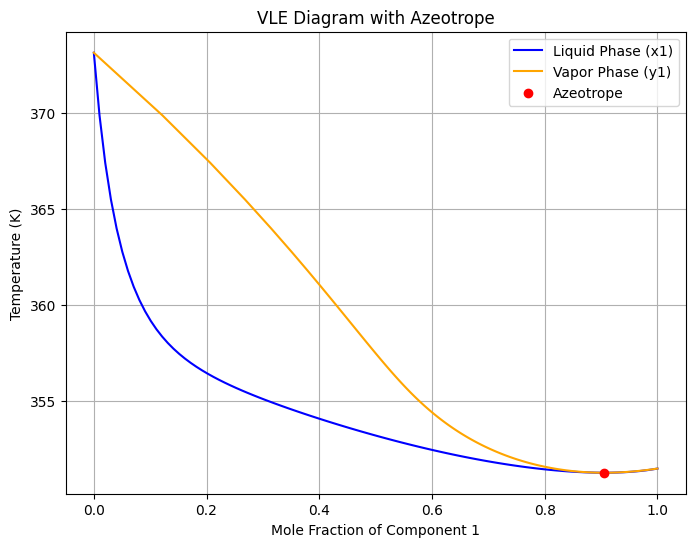

In [22]:
# add azeotrope to plot
plt.figure(figsize=(8, 6))
plt.plot(x[:, 0], T_pyo, label='Liquid Phase (x1)', color='blue')
plt.plot(y_pyo[:, 0], T_pyo, label='Vapor Phase (y1)', color='orange')
plt.scatter(x_az[0,0], T_az, color='red', label='Azeotrope', zorder=5)
plt.xlabel('Mole Fraction of Component 1')
plt.ylabel('Temperature (K)')
plt.title('VLE Diagram with Azeotrope')
plt.legend()
plt.grid()
plt.show()